In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

def load_dataset(path: str) -> pd.DataFrame:
    for enc in ("utf-8", "ISO-8859-1", "latin-1"):
        try:
            df = pd.read_csv(path, encoding=enc, dtype={"Postal Code": str})
            print(f"Loaded successfully with encoding: {enc}")
            return df
        except UnicodeDecodeError:
            print(f"Failed with {enc}, trying the next one...")
        except FileNotFoundError:
            raise SystemExit("File not found")
    raise SystemExit("Could not read the file with any encoding")

DATA_PATH = r"C:\Users\HP\Downloads\Sample - Superstore 2019(Orders) (2).csv"
df_raw = load_dataset(DATA_PATH)

Failed with utf-8, trying the next one...
Loaded successfully with encoding: ISO-8859-1


In [6]:
print(df_raw.shape)
df_raw.info()
df_raw.head()

(9996, 21)
<class 'pandas.DataFrame'>
RangeIndex: 9996 entries, 0 to 9995
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Row ID          9994 non-null   float64
 1   Order ID        9994 non-null   str    
 2   Order Date      9994 non-null   str    
 3   Ship Date       9994 non-null   str    
 4   Ship Mode       9994 non-null   str    
 5   Customer ID     9994 non-null   str    
 6   Customer Name   9994 non-null   str    
 7   Segment         9994 non-null   str    
 8   Country/Region  9994 non-null   str    
 9   City            9994 non-null   str    
 10  State           9994 non-null   str    
 11  Postal Code     9983 non-null   str    
 12  Region          9994 non-null   str    
 13  Product ID      9994 non-null   str    
 14  Category        9994 non-null   str    
 15  Sub-Category    9994 non-null   str    
 16  Product Name    9994 non-null   str    
 17  Sales           9994 non-null   f

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1.0,CA-2018-152156,11/8/2018,11/11/2018,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2.0,0.00,41.9136
1,2.0,CA-2018-152156,11/8/2018,11/11/2018,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3.0,0.00,219.5820
2,3.0,CA-2018-138688,6/12/2018,6/16/2018,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2.0,0.00,6.8714
3,4.0,US-2017-108966,10/11/2017,10/18/2017,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5.0,0.45,-383.0310
4,5.0,US-2017-108966,10/11/2017,10/18/2017,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2.0,0.20,2.5164


In [7]:
df_raw.describe().T

,count,mean,std,min,25%,50%,75%,max
Row ID,9994.0,4997.500000,2885.163629,1.000,2499.25000,4997.5000,7495.750,9994.000
Sales,9994.0,229.858001,623.245101,0.444,17.28000,54.4900,209.940,22638.480
Quantity,9994.0,3.789574,2.225110,1.000,2.00000,3.0000,5.000,14.000
Discount,9994.0,0.156203,0.206452,0.000,0.00000,0.2000,0.200,0.800
Profit,9994.0,28.656896,234.260108,-6599.978,1.72875,8.6665,29.364,8399.976


In [8]:
missing_report = pd.DataFrame({
    "Missing_Values": df_raw.isnull().sum(),
    "Missing_Percentage": (df_raw.isnull().sum() / len(df_raw) * 100).round(3),
})
missing_report

,Missing_Values,Missing_Percentage
Row ID,2,0.02
Order ID,2,0.02
Order Date,2,0.02
Ship Date,2,0.02
Ship Mode,2,0.02
Customer ID,2,0.02
Customer Name,2,0.02
Segment,2,0.02
Country/Region,2,0.02
City,2,0.02


In [9]:
df = df_raw.copy()

# Drop fully empty rows
before = len(df)
df = df.dropna(how="all")
print(f"Fully empty rows removed: {before - len(df)}")

# Remove exact duplicates
before = len(df)
df = df.drop_duplicates()
print(f"Duplicate rows removed: {before - len(df)}")

# Fix data types
df["Row ID"] = df["Row ID"].astype(int)
df["Order Date"] = pd.to_datetime(df["Order Date"], format="%m/%d/%Y")
df["Ship Date"] = pd.to_datetime(df["Ship Date"], format="%m/%d/%Y")

# Remove extra spaces from text columns
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

Fully empty rows removed: 2
Duplicate rows removed: 0


C:\Users\HP\AppData\Local\Temp\ipykernel_34668\1061408973.py:19: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include="object").columns:


In [10]:
postal_map = (
    df.dropna(subset=["Postal Code"])
      .groupby(["City", "State"])["Postal Code"]
      .agg(lambda s: s.mode().iloc[0])
)
missing_postal = df["Postal Code"].isna()
df.loc[missing_postal, "Postal Code"] = [
    postal_map.get((c, s), np.nan)
    for c, s in zip(df.loc[missing_postal, "City"], df.loc[missing_postal, "State"])
]
print("Postal codes still missing:", df["Postal Code"].isna().sum())

Postal codes still missing: 11


In [11]:
print("Ship Date before Order Date:", (df["Ship Date"] < df["Order Date"]).sum())
print("Zero/negative sales rows:", (df["Sales"] <= 0).sum())
print("Duplicate Row IDs:", df["Row ID"].duplicated().sum())

Ship Date before Order Date: 0
Zero/negative sales rows: 0
Duplicate Row IDs: 0


In [12]:
df["Profit_Margin"] = df["Profit"] / df["Sales"]
df["Shipping_Duration"] = (df["Ship Date"] - df["Order Date"]).dt.days
df["Year"] = df["Order Date"].dt.year
df["Month"] = df["Order Date"].dt.month
df["Month_Name"] = df["Order Date"].dt.month_name()
df["Day_Name"] = df["Order Date"].dt.day_name()

def sales_category(x):
    if x <= 100:
        return "Low"
    elif x <= 400:
        return "Medium"
    return "High"

df["Sales_Category"] = df["Sales"].apply(sales_category)
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Quantity,Discount,Profit,Profit_Margin,Shipping_Duration,Year,Month,Month_Name,Day_Name,Sales_Category
0,1,CA-2018-152156,2018-11-08,2018-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,2.0,0.00,41.9136,0.1600,3,2018,11,November,Thursday,Medium
1,2,CA-2018-152156,2018-11-08,2018-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,3.0,0.00,219.5820,0.3000,3,2018,11,November,Thursday,High
2,3,CA-2018-138688,2018-06-12,2018-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,2.0,0.00,6.8714,0.4700,4,2018,6,June,Tuesday,Low
3,4,US-2017-108966,2017-10-11,2017-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,5.0,0.45,-383.0310,-0.4000,7,2017,10,October,Wednesday,High
4,5,US-2017-108966,2017-10-11,2017-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,2.0,0.20,2.5164,0.1125,7,2017,10,October,Wednesday,Low


In [13]:
print(f"Rows before: {len(df_raw)} | Rows after: {len(df)}")
print("Missing values after cleaning:")
print(df.isnull().sum()[df.isnull().sum() > 0])

df.to_csv("superstore_cleaned.csv", index=False)

Rows before: 9996 | Rows after: 9994
Missing values after cleaning:
Postal Code    11
dtype: int64


In [14]:
top_3_customers = df.groupby("Customer Name")["Sales"].sum().sort_values(ascending=False).head(3)
top_3_customers

Customer Name
Sean Miller     25043.050
Tamara Chand    19052.218
Raymond Buch    15117.339
Name: Sales, dtype: float64

In [15]:
category_performance = df.groupby("Category").agg(
    TotalSales=("Sales", "sum"),
    TotalProfit=("Profit", "sum"),
    AverageDiscount=("Discount", "mean"),
    TotalOrders=("Order ID", "nunique"),
).round(2).sort_values("TotalSales", ascending=False)
category_performance

,TotalSales,TotalProfit,AverageDiscount,TotalOrders
Category,,,,
Technology,836154.03,145454.95,0.13,1544
Furniture,741999.80,18451.27,0.17,1764
Office Supplies,719047.03,122490.80,0.16,3742


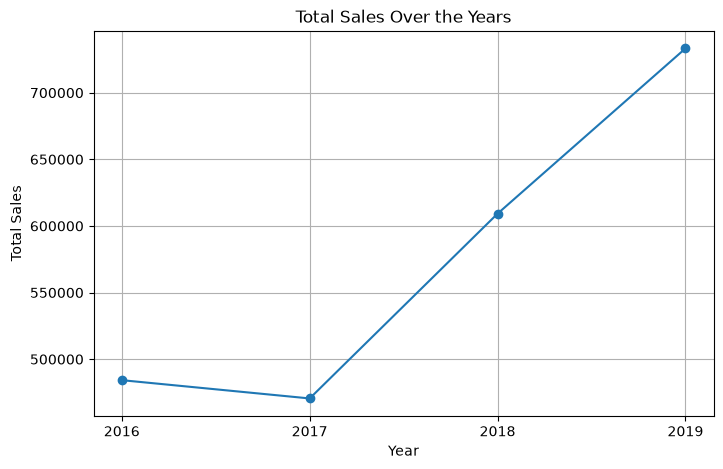

In [16]:
sales_by_year = df.groupby("Year")["Sales"].sum()
plt.figure(figsize=(8, 5))
sales_by_year.plot(kind="line", marker="o")
plt.xticks(sales_by_year.index)
plt.title("Total Sales Over the Years")
plt.xlabel("Year")
plt.ylabel("Total Sales")
plt.grid(True)
plt.show()

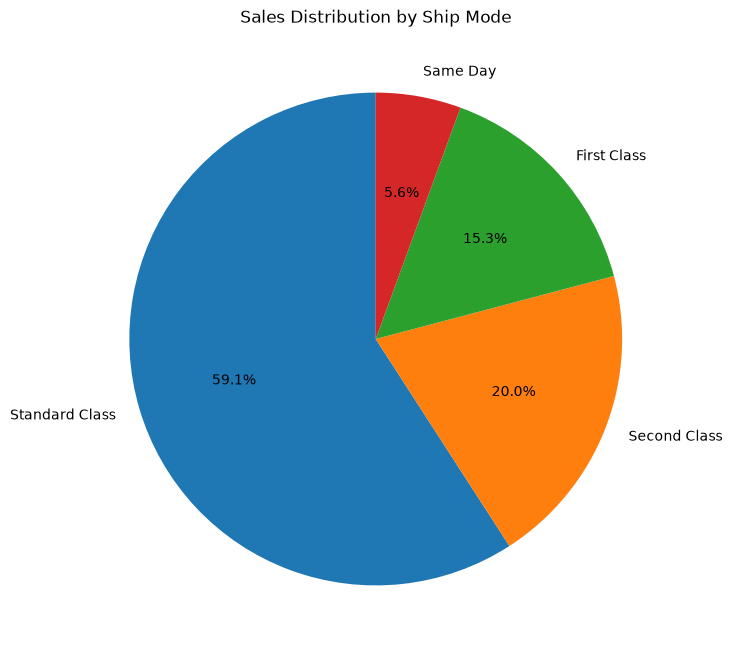

In [17]:
ship_mode_sales = df.groupby("Ship Mode")["Sales"].sum().sort_values(ascending=False)
plt.figure(figsize=(8, 8))
plt.pie(ship_mode_sales, labels=ship_mode_sales.index, autopct="%1.1f%%", startangle=90)
plt.title("Sales Distribution by Ship Mode")
plt.show()